# Aula 6.11 — Exercício Guiado: PCA por Álgebra Linear
**Prática do PDF (slides 42–51): reduzir o Iris de 4 para 2 dimensões.**

A atividade parte de um notebook vazio e desenvolve o PCA com **NumPy** antes de compará-lo com a **SVD** e o **Scikit-learn**. Os rótulos das espécies servem somente para colorir os gráficos; não são utilizados na construção dos componentes principais.

**Objetivo:** centralizar → calcular covariância → encontrar autovalores e autovetores → selecionar componentes → projetar → reconstruir → verificar com SVD e Scikit-learn.

> Convenção deste exercício: PCA sobre as **medidas originais do Iris**, somente com centralização, sem `StandardScaler`. A comparação com padronização aparece no final, como extensão do slide 50.

## Etapa 1 — Imports (slide 44)
Usaremos NumPy para os cálculos matriciais, Matplotlib para os gráficos e o Iris fornecido pelo Scikit-learn. A classe `PCA` só será usada **depois** da implementação manual.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

np.set_printoptions(precision=4, suppress=True)

## Etapa 2 — Carregar o Iris (slide 44)
O conjunto tem 150 flores, **quatro características medidas em centímetros** e três classes de espécie. PCA é não supervisionado: `y` não participa do ajuste.

In [2]:
iris = load_iris()
X = iris.data.astype(float)
y = iris.target
nomes = iris.feature_names
especies = iris.target_names

print("Formato de X:", X.shape)
print("Formato de y:", y.shape)
print("Espécies:", especies)

Formato de X: (150, 4)
Formato de y: (150,)
Espécies: ['setosa' 'versicolor' 'virginica']


## Etapa 3 — Explorar a matriz de dados
Cada **linha** representa uma flor; cada **coluna** é uma característica.

In [3]:
print("Nomes das características:", nomes)
print("Primeiras 5 linhas:\n", X[:5])
print("Classes e frequências:", np.unique(y, return_counts=True))
assert X.shape == (150, 4)
assert len(np.unique(y)) == 3

Nomes das características: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Primeiras 5 linhas:
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
Classes e frequências: (array([0, 1, 2]), array([50, 50, 50]))


## Etapa 4 — Visualizar duas características originais
Os seis gráficos abaixo mostram **todos os pares possíveis das quatro características originais** (mas nenhum mostra as quatro dimensões simultaneamente), antes da projeção PCA.

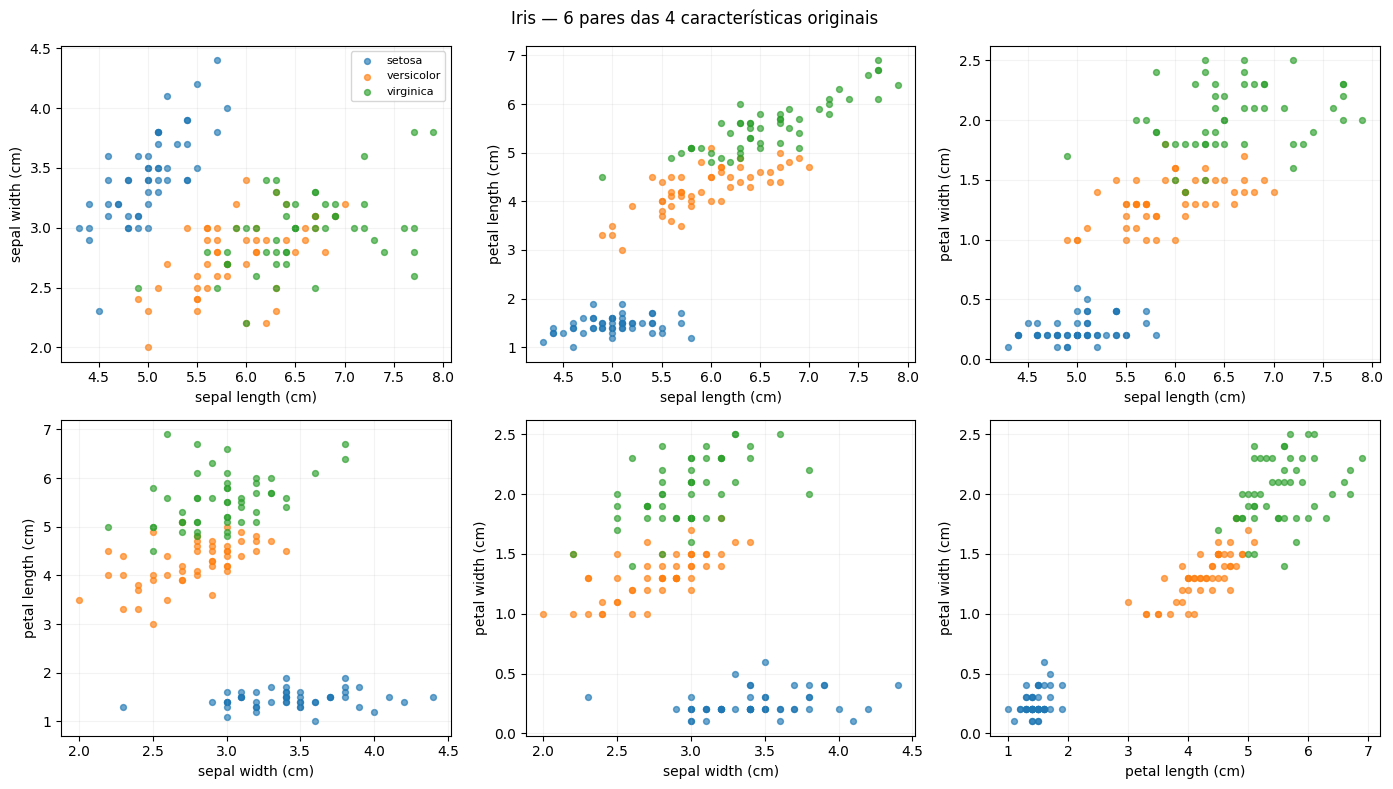

In [4]:
pares = [(i, j) for i in range(4) for j in range(i + 1, 4)]
fig, eixos = plt.subplots(2, 3, figsize=(14, 8))
for ax, (i, j) in zip(eixos.flat, pares):
    for classe, especie in enumerate(especies):
        ax.scatter(X[y == classe, i], X[y == classe, j], label=especie, alpha=0.65, s=18)
    ax.set(xlabel=nomes[i], ylabel=nomes[j])
    ax.grid(alpha=0.15)
eixos[0, 0].legend(fontsize=8)
fig.suptitle("Iris — 6 pares das 4 características originais")
fig.tight_layout()
plt.show()

## Etapa 5 — Calcular a média de cada característica (slide 44)
`axis=0` calcula a média por **coluna**, produzindo um vetor de quatro valores.

In [5]:
media = X.mean(axis=0)
print("Médias das quatro características:", media)
print("Formato:", media.shape)

Médias das quatro características: [5.8433 3.0573 3.758  1.1993]
Formato: (4,)


## Etapa 6 — Centralizar os dados (slides 14–16 e 44)
Subtraímos a média de cada coluna: `X_centralizado = X - media`.

A centralização preserva as distâncias relativas e desloca a origem do sistema para a média dos dados.

In [6]:
X_centralizado = X - media
print("Primeiras 5 linhas centralizadas:\n", X_centralizado[:5])
print("Formato:", X_centralizado.shape)

Primeiras 5 linhas centralizadas:
 [[-0.7433  0.4427 -2.358  -0.9993]
 [-0.9433 -0.0573 -2.358  -0.9993]
 [-1.1433  0.1427 -2.458  -0.9993]
 [-1.2433  0.0427 -2.258  -0.9993]
 [-0.8433  0.5427 -2.358  -0.9993]]
Formato: (150, 4)


## Etapa 7 — Confirmar a centralização
As novas médias devem ser aproximadamente zero (pequenos resíduos numéricos podem aparecer).

In [7]:
medias_apos = X_centralizado.mean(axis=0)
print("Médias após centralização:", medias_apos)
assert np.allclose(medias_apos, 0, atol=1e-12)

Médias após centralização: [-0. -0. -0. -0.]


## Etapa 8 — Construir a matriz de covariância manualmente (slide 45)
Para **covariância amostral**, usamos: `C = (Xc.T @ Xc) / (n - 1)`.

Com quatro características, o resultado será uma matriz **4 × 4**. A diagonal contém variâncias; os demais elementos, covariâncias.

In [8]:
n = X.shape[0]
cov_manual = X_centralizado.T @ X_centralizado / (n - 1)
print("Matriz de covariância manual:\n", cov_manual)
print("Formato:", cov_manual.shape)
assert cov_manual.shape == (4, 4)

Matriz de covariância manual:
 [[ 0.6857 -0.0424  1.2743  0.5163]
 [-0.0424  0.19   -0.3297 -0.1216]
 [ 1.2743 -0.3297  3.1163  1.2956]
 [ 0.5163 -0.1216  1.2956  0.581 ]]
Formato: (4, 4)


## Etapa 9 — Verificar com `np.cov()` (slide 45)
`rowvar=False` informa que as variáveis (características) estão nas colunas.

Matriz de covariância np.cov:
 [[ 0.6857 -0.0424  1.2743  0.5163]
 [-0.0424  0.19   -0.3297 -0.1216]
 [ 1.2743 -0.3297  3.1163  1.2956]
 [ 0.5163 -0.1216  1.2956  0.581 ]]
Coincidem? True


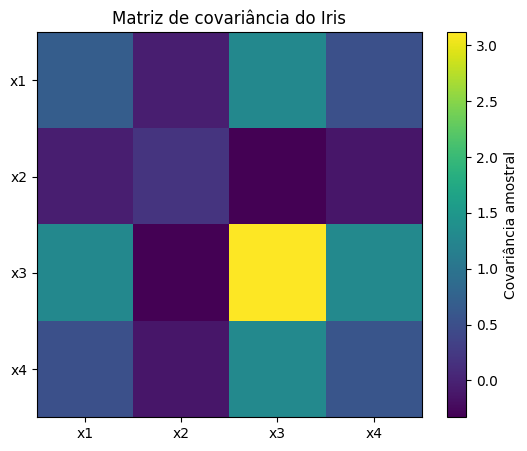

In [9]:
cov_numpy = np.cov(X_centralizado, rowvar=False)
print("Matriz de covariância np.cov:\n", cov_numpy)
print("Coincidem?", np.allclose(cov_manual, cov_numpy))
assert np.allclose(cov_manual, cov_numpy)

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(cov_manual, cmap="viridis")
ax.set_xticks(range(4), [f"x{i+1}" for i in range(4)])
ax.set_yticks(range(4), [f"x{i+1}" for i in range(4)])
ax.set_title("Matriz de covariância do Iris")
fig.colorbar(im, ax=ax, label="Covariância amostral")
plt.show()

## Etapa 10 — Calcular autovalores e autovetores (slide 45)
Usamos `np.linalg.eigh()` porque a matriz de covariância é simétrica. Cada **autovetor** é uma direção principal candidata; seu **autovalor** indica a variância ao longo dela.

In [10]:
autovalores, autovetores = np.linalg.eigh(cov_manual)
print("Autovalores (ordem inicial):", autovalores)
print("Autovetores (colunas):\n", autovetores)
assert np.all(autovalores >= -1e-10)

Autovalores (ordem inicial): [0.0238 0.0782 0.2427 4.2282]
Autovetores (colunas):
 [[ 0.3155  0.582   0.6566 -0.3614]
 [-0.3197 -0.5979  0.7302  0.0845]
 [-0.4798 -0.0762 -0.1734 -0.8567]
 [ 0.7537 -0.5458 -0.0755 -0.3583]]


## Etapa 11 — Ordenar do maior para o menor autovalor (slide 45)
O PCA escolhe primeiro as direções que explicam mais variância. Reordenamos as **colunas** dos autovetores junto com os autovalores.

In [11]:
indices = np.argsort(autovalores)[::-1]
autovalores = autovalores[indices]
autovetores = autovetores[:, indices]
print("Autovalores em ordem decrescente:", autovalores)
print("Primeiro autovetor:", autovetores[:, 0])
assert np.all(np.diff(autovalores) <= 0)

Autovalores em ordem decrescente: [4.2282 0.2427 0.0782 0.0238]
Primeiro autovetor: [-0.3614  0.0845 -0.8567 -0.3583]


## Etapa 12 — Variância explicada (slide 46)
Calculamos `autovalores / soma_dos_autovalores`. O resultado de PC1, PC2, PC3 e PC4 informa qual fração da variância total cada componente representa.

In [12]:
variancia_explicada = autovalores / autovalores.sum()
for i, valor in enumerate(variancia_explicada, start=1):
    print(f"PC{i}: {valor * 100:.2f}%")
print(f"PC1 + PC2: {variancia_explicada[:2].sum() * 100:.2f}%")
assert np.isclose(variancia_explicada.sum(), 1.0)

PC1: 92.46%
PC2: 5.31%
PC3: 1.71%
PC4: 0.52%
PC1 + PC2: 97.77%


## Etapa 13 — Variância explicada acumulada (slides 36 e 46)
A soma acumulada ajuda a escolher o número de componentes. A meta de 95% é apenas um exemplo, não uma obrigação universal.

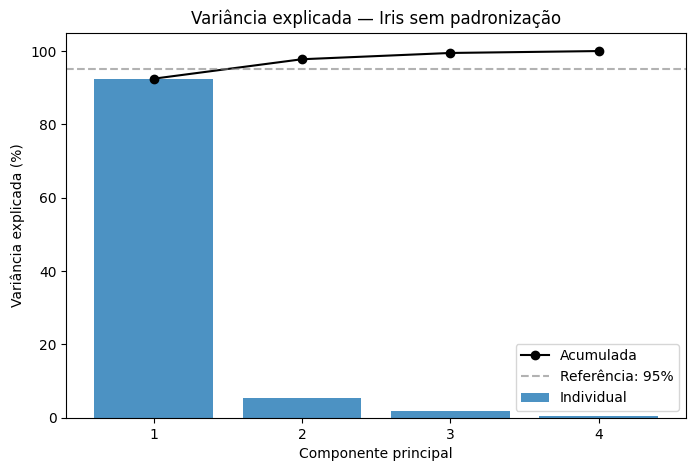

Acumulada (%): [ 92.46  97.77  99.48 100.  ]


In [13]:
variancia_acumulada = np.cumsum(variancia_explicada)
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(range(1, 5), variancia_explicada * 100, alpha=0.8, label="Individual")
ax.plot(range(1, 5), variancia_acumulada * 100, marker="o", color="black", label="Acumulada")
ax.axhline(95, linestyle="--", color="gray", alpha=0.6, label="Referência: 95%")
ax.set(xlabel="Componente principal", ylabel="Variância explicada (%)", xticks=range(1, 5), ylim=(0, 105), title="Variância explicada — Iris sem padronização")
ax.legend()
plt.show()
print("Acumulada (%):", np.round(variancia_acumulada * 100, 2))

## Etapa 14 — Selecionar dois componentes (slide 47)
Criamos `W`, matriz de projeção **4 × 2**, usando os dois autovetores associados aos maiores autovalores.

In [14]:
k = 2
W = autovetores[:, :k]
print("Matriz W:\n", W)
print("Formato:", W.shape)
print("W.T @ W (deve ser identidade):\n", W.T @ W)
assert W.shape == (4, 2)
assert np.allclose(W.T @ W, np.eye(2))

Matriz W:
 [[-0.3614  0.6566]
 [ 0.0845  0.7302]
 [-0.8567 -0.1734]
 [-0.3583 -0.0755]]
Formato: (4, 2)
W.T @ W (deve ser identidade):
 [[1. 0.]
 [0. 1.]]


## Etapa 15 — Projetar o Iris de 4D para 2D (slide 47)
`Z = X_centralizado @ W`: o formato passa de **150 × 4** para **150 × 2**.

In [15]:
Z = X_centralizado @ W
print("Formato de Z:", Z.shape)
print("Primeiras 5 flores projetadas:\n", Z[:5])
assert Z.shape == (150, 2)

Formato de Z: (150, 2)
Primeiras 5 flores projetadas:
 [[ 2.6841  0.3194]
 [ 2.7141 -0.177 ]
 [ 2.889  -0.1449]
 [ 2.7453 -0.3183]
 [ 2.7287  0.3268]]


## Etapa 16 — Visualizar o Iris em duas dimensões (slide 48)
O modelo PCA **não usa o rótulo `y` no cálculo**. Usamos `y` somente para colorir os pontos no gráfico, facilitando a interpretação das espécies.

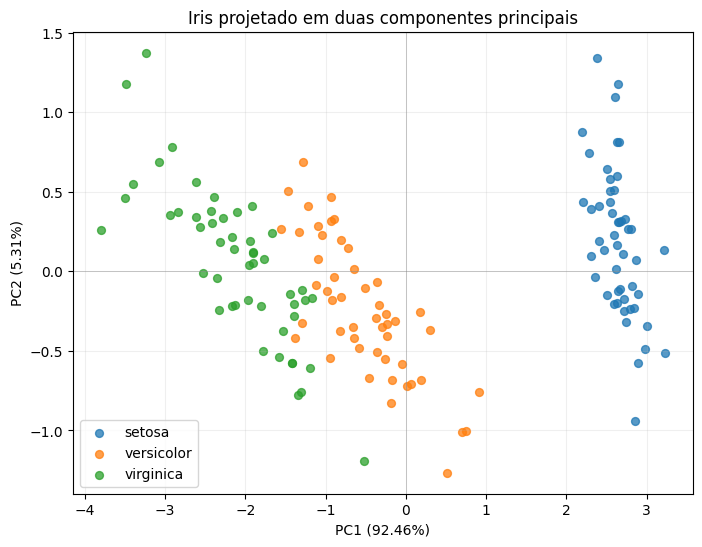

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
for classe, especie in enumerate(especies):
    ax.scatter(Z[y == classe, 0], Z[y == classe, 1], label=especie, alpha=0.75, s=32)
ax.set(xlabel=f"PC1 ({variancia_explicada[0]*100:.2f}%)", ylabel=f"PC2 ({variancia_explicada[1]*100:.2f}%)", title="Iris projetado em duas componentes principais")
ax.axhline(0, color="gray", linewidth=0.7, alpha=0.4)
ax.axvline(0, color="gray", linewidth=0.7, alpha=0.4)
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## Etapa 17 — Reconstruir aproximadamente os dados originais (slide 47)
A reconstrução no espaço das quatro características é `X_reconstruido = Z @ W.T + media`.

Por termos descartado componentes, os valores reconstruídos **não são exatamente** os originais.

Formato reconstruído: (150, 4)
Primeira flor original: [5.1 3.5 1.4 0.2]
Primeira flor reconstruída: [5.083  3.5174 1.4032 0.2135]
MSE de reconstrução: 0.025341


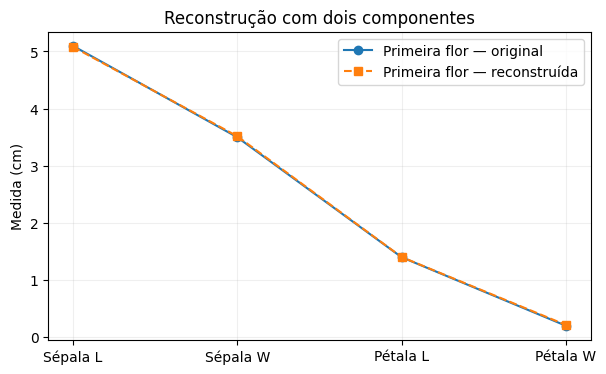

In [17]:
X_reconstruido = Z @ W.T + media
mse_reconstrucao = np.mean((X - X_reconstruido) ** 2)
print("Formato reconstruído:", X_reconstruido.shape)
print("Primeira flor original:", X[0])
print("Primeira flor reconstruída:", X_reconstruido[0])
print(f"MSE de reconstrução: {mse_reconstrucao:.6f}")
assert X_reconstruido.shape == X.shape

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(X[0], "o-", label="Primeira flor — original")
ax.plot(X_reconstruido[0], "s--", label="Primeira flor — reconstruída")
ax.set(xticks=range(4), xticklabels=["Sépala L", "Sépala W", "Pétala L", "Pétala W"], ylabel="Medida (cm)", title="Reconstrução com dois componentes")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## Etapa 18 — PCA por SVD (slide 49)
Fatoramos a **mesma matriz centralizada** por `Xc = U @ diag(S) @ Vt`.

Os autovalores da covariância são iguais a `S**2 / (n-1)`. Os dois primeiros vetores singulares direitos descrevem o mesmo subespaço principal. **Os sinais podem ser invertidos**.

In [18]:
U, S, Vt = np.linalg.svd(X_centralizado, full_matrices=False)
valores_svd = S**2 / (n - 1)
W_svd = Vt[:2].T
Z_svd = X_centralizado @ W_svd
X_reconstruido_svd = Z_svd @ W_svd.T + media
print("Singular values:", S)
print("Autovalores via SVD:", valores_svd)
print("Equivalência de autovalores:", np.allclose(valores_svd, autovalores))
print("Reconstruções equivalentes:", np.allclose(X_reconstruido_svd, X_reconstruido))
assert np.allclose(valores_svd, autovalores, atol=1e-10)
assert np.allclose(X_reconstruido_svd, X_reconstruido, atol=1e-10)

Singular values: [25.1     6.0131  3.4137  1.8845]
Autovalores via SVD: [4.2282 0.2427 0.0782 0.0238]
Equivalência de autovalores: True
Reconstruções equivalentes: True


## Etapa 19 — Comparar com PCA do Scikit-learn (slide 49)
Somente agora usamos a classe pronta `PCA(n_components=2)`.

Como o Scikit-learn centraliza internamente, `fit_transform` recebe `X` **sem fazer centralização manual adicional**.

Os sinais de PC1 e PC2 podem diferir entre NumPy e Scikit-learn, mas a variância explicada e a reconstrução devem concordar.

Formas — manual, SVD e sklearn: (150, 2) (150, 2) (150, 2)
Variância explicada manual: [0.9246 0.0531]
Variância explicada sklearn: [0.9246 0.0531]
Reconstruções manual vs. sklearn: True


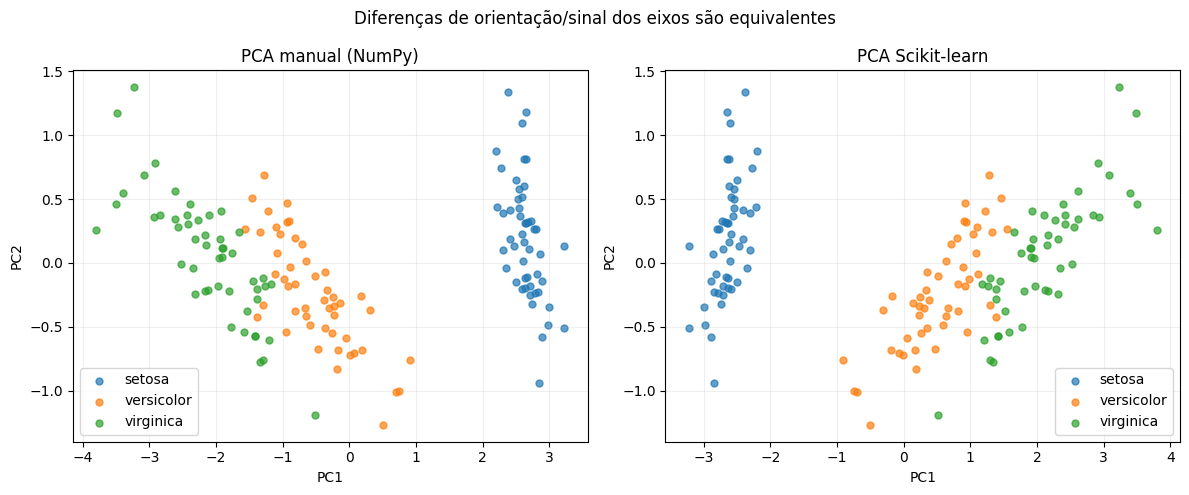

In [19]:
pca_sklearn = PCA(n_components=2)
Z_sklearn = pca_sklearn.fit_transform(X)
X_reconstruido_sklearn = pca_sklearn.inverse_transform(Z_sklearn)

print("Formas — manual, SVD e sklearn:", Z.shape, Z_svd.shape, Z_sklearn.shape)
print("Variância explicada manual:", np.round(variancia_explicada[:2], 6))
print("Variância explicada sklearn:", np.round(pca_sklearn.explained_variance_ratio_, 6))
print("Reconstruções manual vs. sklearn:", np.allclose(X_reconstruido, X_reconstruido_sklearn))
assert np.allclose(variancia_explicada[:2], pca_sklearn.explained_variance_ratio_)
assert np.allclose(X_reconstruido, X_reconstruido_sklearn, atol=1e-10)

fig, eixos = plt.subplots(1, 2, figsize=(12, 5))
for classe, especie in enumerate(especies):
    eixos[0].scatter(Z[y == classe, 0], Z[y == classe, 1], label=especie, s=25, alpha=0.7)
    eixos[1].scatter(Z_sklearn[y == classe, 0], Z_sklearn[y == classe, 1], label=especie, s=25, alpha=0.7)
eixos[0].set(title="PCA manual (NumPy)", xlabel="PC1", ylabel="PC2")
eixos[1].set(title="PCA Scikit-learn", xlabel="PC1", ylabel="PC2")
for eixo in eixos:
    eixo.grid(alpha=0.2)
    eixo.legend()
plt.suptitle("Diferenças de orientação/sinal dos eixos são equivalentes")
plt.tight_layout()
plt.show()

## Etapa 20 — Efeito da padronização e conclusão (slide 50)
O slide 50 contrasta o PCA em dados apenas **centralizados** com o PCA após `StandardScaler`. A mudança de escala pode alterar os componentes e as porcentagens.

Conclua: o PCA preservou aproximadamente 97,77% da variância usando **PC1 + PC2 nas medidas originais**. Os rótulos das espécies foram usados apenas para visualização.

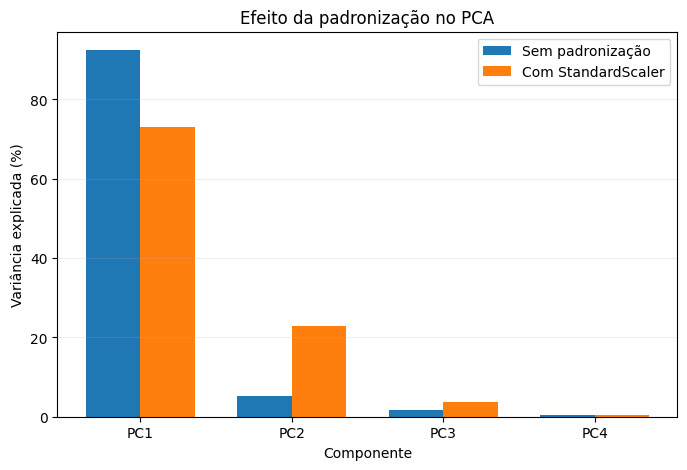

PC1 + PC2 sem padronização: 97.77%
PC1 + PC2 com StandardScaler: 95.81%
Conclusão: PCA aprende direções de maior variância; os resultados dependem da escala das características.


In [20]:
padronizador = StandardScaler()
X_padronizado = padronizador.fit_transform(X)
pca_padronizado = PCA(n_components=4)
pca_padronizado.fit(X_padronizado)

variancia_original = variancia_explicada * 100
variancia_padronizada = pca_padronizado.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(8, 5))
eixos_x = np.arange(4)
largura = 0.36
ax.bar(eixos_x - largura/2, variancia_original, largura, label="Sem padronização")
ax.bar(eixos_x + largura/2, variancia_padronizada, largura, label="Com StandardScaler")
ax.set(xticks=eixos_x, xticklabels=["PC1", "PC2", "PC3", "PC4"], xlabel="Componente", ylabel="Variância explicada (%)", title="Efeito da padronização no PCA")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.show()

print(f"PC1 + PC2 sem padronização: {variancia_explicada[:2].sum()*100:.2f}%")
print(f"PC1 + PC2 com StandardScaler: {pca_padronizado.explained_variance_ratio_[:2].sum()*100:.2f}%")
print("Conclusão: PCA aprende direções de maior variância; os resultados dependem da escala das características.")

### Observação adicional — PCA em uma tarefa supervisionada (slide 51)
Neste exercício o PCA foi exploratório. **Quando for usado para classificação**, faça a separação entre treino/teste **antes** de ajustar a transformação e utilize um `Pipeline` para evitar vazamento de dados. O exemplo abaixo é complementar, não altera o PCA manual anterior.

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

modelo_supervisionado = make_pipeline(
    PCA(n_components=2),
    LogisticRegression(max_iter=1000)
)
modelo_supervisionado.fit(X_treino, y_treino)
print(f"Acurácia no teste (exemplo com Pipeline): {modelo_supervisionado.score(X_teste, y_teste):.4f}")

Acurácia no teste (exemplo com Pipeline): 0.9000


## Checklist de conclusão
- [ ] Consegui explicar a centralização das quatro colunas.
- [ ] Sei por que a matriz de covariância é 4 × 4.
- [ ] Sei o que autovalores e autovetores representam.
- [ ] Consegui reduzir a matriz 150 × 4 para 150 × 2.
- [ ] Sei interpretar a variância explicada.
- [ ] Entendo que os sinais dos componentes podem diferir entre implementações.
- [ ] Sei por que padronizar pode mudar os resultados.
- [ ] Sei evitar vazamento de dados quando PCA participa de uma tarefa supervisionada.

**Fonte didática:** `6.11 - PCA.pdf`, slides 42–51. A divisão em 20 etapas é uma organização prática dessas operações para execução independente.